# Lista 1 - Symulacje komputerowe

## Zadanie 1 

Niech $ P_o$ - prawdopodobieństwo zwycięstwa Grzesia (ORR) w stanie O - orzeł. Wiemy, że obie sekwencje zaczynają się od O zatem jest to sensowny punkt startowy. Policzmy prawdopodobieństwo przejscia do kolejnych stanów $P_oo, P_or$ i prawdopodobieństwo wygranej w każdym z nich. 
$$ \begin{cases}
P_O = \frac{1}{2} P_{OO} + \frac{1}{2} P_{OR} \\
P_{OR} = \frac{1}{2} P_O + \frac{1}{2} (1)
\end{cases} $$

$$\begin{cases}
P_O = \frac{1}{2} P_{OR} \\
P_{OR} = \frac{1}{2} P_O + \frac{1}{2}
\end{cases}$$

$$P_O = \frac{1}{3}$$

Prawdopodobieństwo wygranej Grzesia wynosi $\frac{1}{3}$, a Jasia $\frac{2}{3}$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import random

In [2]:
def simulate_coin_toss(sequence1, sequence2, max_trials = 20000):
    if len(sequence1) != len(sequence2):
        raise ValueError("Both sequences must be of the same length.")
    possible_states = ["O", "R"]
    min_length = len(sequence1)
    s1_wins = 0
    s2_wins = 0
    seq1_list = list(sequence1)
    seq2_list = list(sequence2)

    trial = 1
    while  trial < max_trials:
        start_state = [random.choice(possible_states) for _ in range(min_length)] 
        win = False
        while not win:
            if start_state == seq1_list:
                s1_wins += 1
                win = True
            elif start_state == seq2_list:
                s2_wins += 1
                win = True
            start_state.append(random.choice(possible_states))
            start_state.pop(0)
        trial += 1
    return (s1_wins / (s1_wins + s2_wins), s2_wins / (s1_wins + s2_wins))

In [3]:
seq_prob = simulate_coin_toss(sequence1="OOR", sequence2="ORR")
print(seq_prob)

(0.6628831441572078, 0.33711685584279216)


# 2. 
Zróbmy ogólniejszy przypadek dla dowolnej liczby graczy, i z większą możliwością doboru sekwencji.

In [ ]:
def coin_seq_toss(*args, possible_states=["O", "R"], max_trials=20000):
    """args format: [sequence_1, sequence_2, ...]
    sequences must be different and the same ;length 
    returns: winner_index"""
    if any(len(seq) != len(args[0]) for seq in args):
        raise ValueError("All sequences must be of the same length.")
    start_state = [random.choice(possible_states) for _ in range(len(args[0]))] #
    counter = 0 # checker for infinite loops
    while counter < max_trials:
        for index, seq in enumerate(args):
            if list(seq) == start_state: 
                return index 
        start_state.append(random.choice(possible_states))
        start_state.pop(0)
        counter += 1
    if counter >=max_trials: 
        raise RuntimeError("Max trials reached without a winner.")
    return index # sequence index that won

def match_until_bankrupcy(*args, possible_states=["O", "R"], max_trials=20000):
    """args format: [(sequence_1, capital_1), (sequence_2, capital_2), ...]
    sequences must be different and the same ;length 
    returns: winner_index"""
    sequences = [seq for seq, _ in args]
    capital = [capital for _, capital in args]
    num_players = len(args)

    # We assume that game stops when at least one player goes bankrupt (capital <= 0)
    while min(capital) > 0:  # continue until at least one player goes bankrupt
        winner_index = coin_seq_toss(*sequences, possible_states=possible_states, max_trials=max_trials)
        for i in range(num_players):
            if i != winner_index:
                capital[i] -= 1  # each loser pays 1
            else:
                capital[winner_index] += num_players - 1  # winner gains 1 from each player
    bankrupt_players = [i for i, cap in enumerate(capital) if cap <= 0] # finding all bankrupt players

    return bankrupt_players

def get_bankruptcy_probabilities(*args, possible_states=["O", "R"], simulation_trials=20000):
    """args format: [(sequence_1, capital_1), (sequence_2, capital_2), ...]"""
    if len(args) < 2:
        raise ValueError("At least two sequences must be provided.")
    
    num_players = len(args)
    bankruptcy_counts = [0] * len(args)
    for _ in range(simulation_trials):
        bankrupt_players = match_until_bankrupcy(*args, possible_states=possible_states)
        for player in bankrupt_players:
            bankruptcy_counts[player] += 1
    probabilities = [count / simulation_trials for count in bankruptcy_counts] 
    return probabilities

In [5]:
print(get_bankruptcy_probabilities(("OOR", 5), ("ORR", 25), simulation_trials=1000))

[0.033, 0.967]


Widać że prawdopodobieństwo bankructwa grzesia jest dużo wyższe pomimo większego kapitału

## 3.

Narysujmy wykres bankructwa dla Jasia i Grzesia w zależności od kapitałów początkowych. Weźmy przedział kapitału od 1 do 20. Zakładamy, że drugi gracz ma 10 BTC.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def plot_bankrupcy_prob_2players(seq1, seq2, possible_states=["O", "R"], simulation_trials=1000, start=1, end=20, step=1, sec_player_capital = 10):


    capital_range = np.linspace(start, end, int((end - start) / step))
    seq1_prob = []
    # 1 player
    for num in capital_range:
        probabilities = get_bankruptcy_probabilities((seq1, num), (seq2, sec_player_capital), possible_states=possible_states, simulation_trials=simulation_trials)
        seq1_prob.append(probabilities[0])
    plt.plot(capital_range, seq1_prob, label='Sequence 1', color='blue')
    plt.xlabel('Capital')
    plt.ylabel('Frequency')
    plt.title(f'Probability of Bankruptcy for {seq1} vs {seq2}: Capital = {sec_player_capital}')
    plt.legend()
    plt.show()

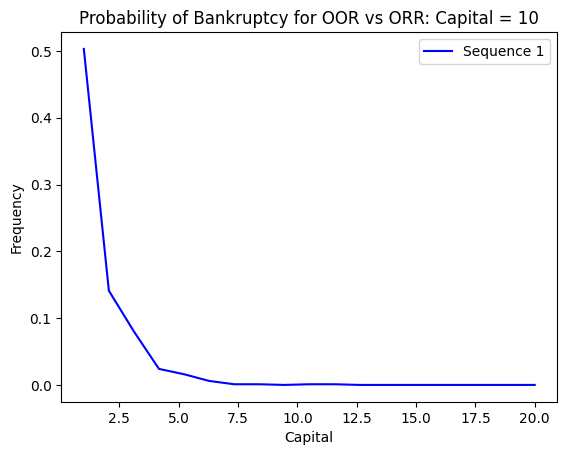

In [7]:
plot_bankrupcy_prob_2players("OOR", "ORR")

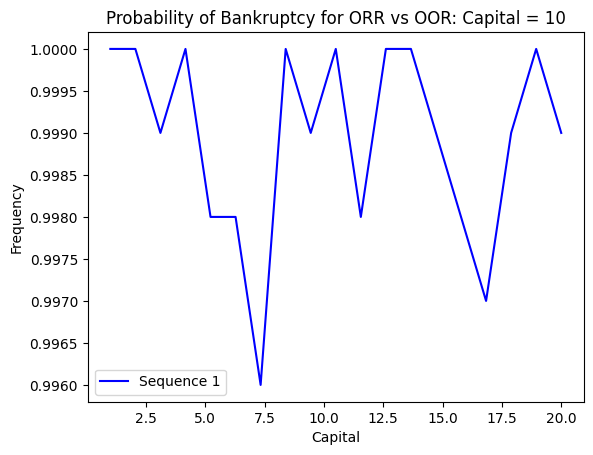

In [44]:
plot_bankrupcy_prob_2players("ORR", "OOR")

Widać, że wraz ze wzrostem kapitału prawdopodobieństwo ruiny rośnie do ok. 1 lub spada do 0.

## 4.
Prawdopodobieństwo zwycięstwa Tosi możemy wyznaczyć w podobny sposób co prawdopodobieństwo wygranej Grzesia. Warto zauważyć, że jak Tosia dołączy do gry to prawdopodobieństwa zwycięstwa Jasia i Grzesia się zmienią. 

$$ \begin{cases}
P_{\emptyset} = \frac{1}{2} P_O + \frac{1}{2} P_R \\
P_R = \frac{1}{2} P_{RR} + \frac{1}{2} P_{RO} \\
P_{RR} = \frac{1}{2}P_{RRR} + \frac{1}{2} P_{RRO} \\
P_{OO} = \frac{1}{2}P_{OOR} + \frac{1}{2}P_{OOO} \\
P_{RO} = \frac{1}{2}P_{OR} + \frac{1}{2}P_{OO} \\
P_{OR} = \frac{1}{2}P_{ORO} + \frac{1}{2}P_{ORR} \\
P_O = \frac{1}{2} P_O + \frac{1}{2} P_R
\end{cases} $$
Widać, że jeśli otrzymamy gdziekolwiek O  to Tosia nie ma szans wygrać bo albo będzie ORR zanim bedzie RRR - Grześ ją blokuje. Zatem $P_O = 0$. Upraszczamy:

$$ P_{\emptyset} = \frac{1}{8} $$

### Wyznaczanie prawdopodobieństw dla wszystkich graczy. 
Można oblicz je jak wyżej albo skorzystać z algorytmu Conway'a. Wyznaczmy najpierw wartości nakładania - jak bardzo nakładają się sekwencje na siebie. Polega to na porównywaniu prefiksów i sufiksów danych sekwencji. 

$$(A \mu B) = \sum_{k=1}^{n} \mathbb{I}_k \cdot 2^{k-1}$$
$$\sum_{i=1}^{N} p_i = 1$$
$$N - \text{długość sekwencji} \\
 \mathbb{I}_k- \text{indykator 1 jesli sie sekwencje pokrywaja 0 jesli nie} \\
$$
np. wyliczmy wartość nakładania dla RRR i ORR:
porównujemy 

prefiks(RRR) - R z sufiksem(ORR)  - R, są takie same $2^{1 - 1}$

następnie RR z RR, takie same $ = 2^{2-1}$

RRR z ORR, inne  = 0

##### Obliczenie prawdopodobieństw
Sprowadza się do rozwiązania układu równań liniowych. 
$$
\begin{aligned}
&\sum_{j=1}^{N} p_j (S_i \mu S_j) = \lambda && \text{for } i \in \{1, \dots, N\} \\
&\sum_{i=1}^{N} p_i = 1
\end{aligned}
$$

Końcowo dostajemy:

$$ P_{jas} = \frac{7}{12}, \space \space P_{grzes} = \frac{7}{24}, \space \space P_{tosia} = \frac{1}{8}$$

In [45]:
print(get_bankruptcy_probabilities(("OOR", 1), ("ORR", 1),("RRR", 1) , simulation_trials=1000))

[0.407, 0.718, 0.875]


Potwierdzają nasze analityczne rozwiązanie symulacje. 


## Czy można wyrównać szanse kapitałem?

Policzmy wartość oczekiwaną zmiany kapitału po każdej grze(J - Jaś, G - Grześ, T - Tosia): 

$ \mathbb{E}[\Delta C_J] = 2 \cdot (14/24) - 1 \cdot (10/24) = +18/24 = \mathbf{+0,75}$

$\mathbb{E}[\Delta C_G] = 2 \cdot (7/24) - 1 \cdot (17/24) = -3/24 = \mathbf{-0,125}$

$\mathbb{E}[\Delta C_T] = 2 \cdot (3/24) - 1 \cdot (21/24) = -15/24 = \mathbf{-0,625} $

Widać, że wartości oczekiwane są drastycznie różne. Jaś nawet przy bardzo małym kapitale jest w stanie z dużym prawdopodobieństwem nie zbankrutować. Nie da się wyznaczyć kapitałów tak aby gracze mieli taką samą szansze na wygraną. 

In [46]:
print(get_bankruptcy_probabilities(("OOR", 2), ("ORR", 300),("RRR",1410) , simulation_trials=1000))

[0.25, 0.329, 0.422]


##  5.
interesują nas sekwencje które nie nachodzą na siebie lub nachodzą na siebie w takim samym stopniu tzn. wartość nakładania jest taka sama np.: RRR i  OOO, ORO i ROR

In [35]:
# OOO, RRR
print(get_bankruptcy_probabilities(("RRR", 25), ("OOO", 25)))
# ORO, ROR
print(get_bankruptcy_probabilities(("ORO", 25), ("ROR", 25)))

[0.50055, 0.49945]
[0.5048, 0.4952]


##  6. 
Dodajmy do funkcji zdefinowanych wyżej prawdopodobieństwo. 

In [36]:
import random 

def coin_seq_toss_p(*args, states, prob, max_trials=20000):
    """args format: [sequence_1, sequence_2, ...]
    sequences must be different and the same ;length 
    returns: winner_index"""
    if any(len(seq) != len(args[0]) for seq in args):
        raise ValueError("All sequences must be of the same length.")

    start_state = [np.random.choice(states, p=prob) for _ in range(len(args[0]))] #
    counter = 0 # checker for infinite loops
    while counter < max_trials:
        for index, seq in enumerate(args):
            if list(seq) == start_state: 
                return index # index that won
        start_state.append(np.random.choice(states, p=prob))
        start_state.pop(0)
        counter += 1
    if counter >=max_trials: 
        raise RuntimeError("Max trials reached without a winner.")

def match_until_bankrupcy_p(*args, states, prob, max_trials=20000):
    """args format: [(sequence_1, capital_1), (sequence_2, capital_2), ...]
    sequences must be different and the same ;length 
    returns: winner_index"""
    sequences = [seq for seq, _ in args]
    capital = [capital for _, capital in args]
    num_players = len(args)

    # We assume that game stops when at least one player goes bankrupt (capital <= 0)
    while min(capital) > 0:  # continue until at least one player goes bankrupt
        winner_index = coin_seq_toss_p(*sequences, states=states, prob=prob,  max_trials=max_trials)
        for i in range(num_players):
            if i != winner_index:
                capital[i] -= 1  # each loser pays 1
            else:
                capital[winner_index] += num_players - 1  # winner gains 1 from each player
    bankrupt_players = [i for i, cap in enumerate(capital) if cap <= 0] # finding all bankrupt players

    return bankrupt_players


def get_bankruptcy_probabilities_p(*args, states=["O", "R"],prob=[0.5, 0.5], simulation_trials=20000):
    """args format: [(sequence_1, capital_1), (sequence_2, capital_2), ...]"""
    if len(args) < 2:
        raise ValueError("At least two sequences must be provided.")
   
    if  not 0.99 < sum(prob) < 1.01:
        raise ValueError("probability dosent sum to 1 ") 
    num_players = len(args)
    bankruptcy_counts = [0] * len(args)
    valid_trials = 0
    for _ in range(simulation_trials):
        try:
            bankrupt_players = match_until_bankrupcy_p(*args, states=states, prob=prob)
            for player in bankrupt_players:
                bankruptcy_counts[player] += 1
            valid_trials += 1
        except RuntimeError:
            continue

    probabilities = [count / valid_trials for count in bankruptcy_counts] 
    return probabilities

In [37]:
print(get_bankruptcy_probabilities_p(("ORR", 1), ("OOR", 1), simulation_trials=1000, prob=[0.3,0.7]))

[0.371, 0.629]


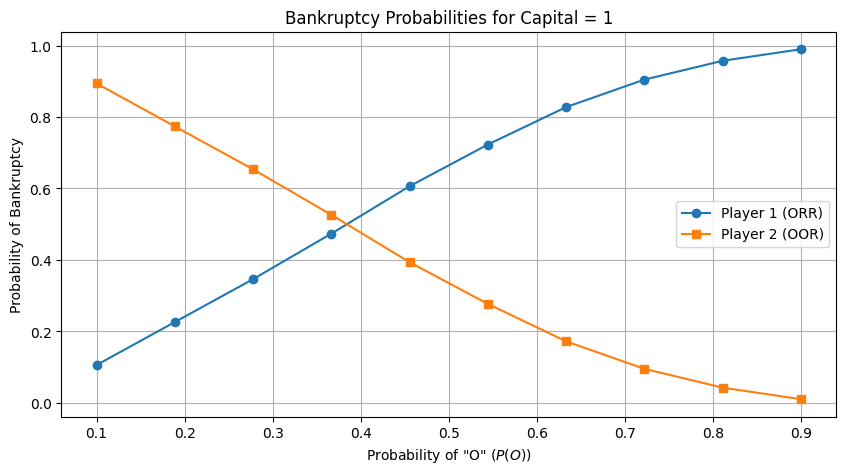

In [38]:
p_range = np.linspace(0.1, 0.9, 10)
seq1, seq2 = "ORR", "OOR"
c1_probs = []
c2_probs = []

for p_o in p_range:
    res = get_bankruptcy_probabilities_p((seq1, 1), (seq2, 1), prob=[p_o, 1-p_o])
    c1_probs.append(res[0])
    c2_probs.append(res[1])

plt.figure(figsize=(10, 5))
plt.plot(p_range, c1_probs, 'o-', label=f'Player 1 ({seq1})')
plt.plot(p_range, c2_probs, 's-', label=f'Player 2 ({seq2})')
plt.xlabel('Probability of "O" ($P(O)$)')
plt.ylabel('Probability of Bankruptcy')
plt.title('Bankruptcy Probabilities for Capital = 1')
plt.legend()
plt.grid(True)
plt.show()

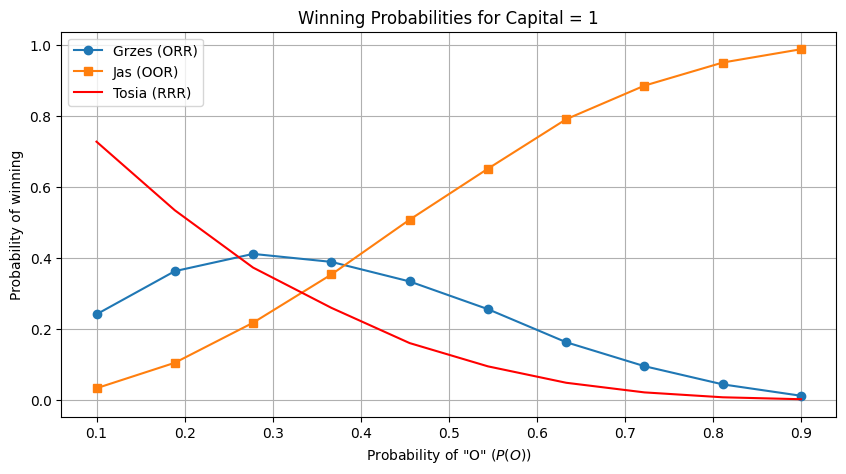

In [39]:
p_range = np.linspace(0.1, 0.9, 10)
seq1, seq2, seq3 = "ORR", "OOR", "RRR"
c1_probs = []
c2_probs = []
c3_probs = []
for p_o in p_range:
    res = get_bankruptcy_probabilities_p((seq1, 1), (seq2, 1), (seq3,1), prob=[p_o, 1-p_o])
    c1_probs.append(1-res[0])
    c2_probs.append(1-res[1])
    c3_probs.append(1-res[2])

plt.figure(figsize=(10, 5))
plt.plot(p_range, c1_probs, 'o-', label=f'Grzes ({seq1})')
plt.plot(p_range, c2_probs, 's-', label=f'Jas ({seq2})')
plt.plot(p_range, c3_probs, 'r-', label=f'Tosia ({seq3})')
plt.xlabel('Probability of "O" ($P(O)$)')
plt.ylabel('Probability of winning')
plt.title('Winning Probabilities for Capital = 1')
plt.legend()
plt.grid(True)
plt.show()

Dla dwóch graczy gra może być sprawiedliwa, dla sytuacji 3 graczy widać że nie możemy dobrać tak prawdopodobieństw aby prawdopodobieństwa zwycięstwa. 

# Zadanie 2 

## Problem kolekcjonera

## a)

In [40]:
def collectioner_problem(num_items, simulation_trials=20000):
    """num_items: total number of unique items to collect - int, equal probability"""
    appeared_items = set()
    counter = 0 
    for _ in range(simulation_trials):
        while len(appeared_items) < num_items:
            new_item = random.randint(1, num_items)
            appeared_items.add(new_item)
            counter += 1
        appeared_items.clear() # reset for next trial


    return counter / simulation_trials
print(collectioner_problem(6))

14.7871


## b) 

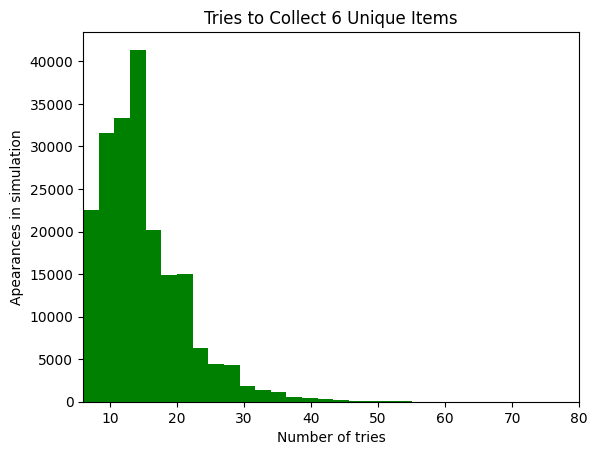

In [41]:
import random
import matplotlib.pyplot as plt
import numpy as np 

def collectioner_problem_tries(num_items, simulation_trials=20000):
    """num_items: total number of unique items to collect - int, equal probability"""
    appeared_items = set()
    counter = 0 
    num_of_tries =[]
    for _ in range(simulation_trials):
        while len(appeared_items) < num_items:
            new_item = random.randint(1, num_items)
            appeared_items.add(new_item)
            counter += 1
        num_of_tries.append(counter)
        counter = 0
        appeared_items.clear() # reset for next trial
    return num_of_tries

def plot_collectioner_problem(num_items, simulation_trials=200000):
    tries = collectioner_problem_tries(num_items, simulation_trials)
    plt.hist(tries, bins=30, density=False, color='g')
    plt.xlim(6, 80)
    plt.xlabel('Number of tries')
    plt.ylabel('Apearances in simulation')
    plt.title(f'Tries to Collect {num_items} Unique Items')
    plt.show()

plot_collectioner_problem(6)



## Kto pierwszy wyrzuci 6 
policzmy to analitycznie. Na początku prawdopodobienstwo wygranej jest równe $ \frac{1}{6} $, kiedy nie wyrzucimy 6 to gracz drugi też nie może wyrzucić 6 czyli $ \frac{1}{6} + \frac{5}{6} \cdot \frac{5}{6} \cdot \frac{1}{6} $ itd. możemy zapisać to za pomocą szeregu geometrycznego.

$$ 
\sum_{i=0}^{\infty} \frac{1}{6} \left( \frac{5}{6} \right)^{2i} = 
\frac{1}{6} \sum_{i=0}^{\infty} \left( \frac{25}{36} \right)^i = 
\frac{1}{6} \cdot \frac{36}{11} = \frac{6}{11} \approx 0,54 $$

In [42]:
def first_6_roll(simulation_trials=1000000, max_loop=3000):
    player1_count = 0
    player2_count = 0
    for _ in range(simulation_trials):
        counter = 0
        while max_loop > counter:
            # first player roll:
            if random.random() < 1 / 6:  # Player 1 rolls a 6
                player1_count += 1
                break 
            # second player roll
            elif random.random() < 1 / 6:  # Player 2 rolls a 6
                player2_count += 1
                break 
            counter += 1
    return [player1_count / simulation_trials, player2_count / simulation_trials]

print(first_6_roll())

[0.545151, 0.454849]


In [43]:
import random 
def roll_6_improved(simulation_trials=1000000, max_loop=3000):
    player1_count = 0
    player2_count = 0
    for _ in range(simulation_trials):
        counter = 0
        while max_loop > counter:
            player_1 = random.randint(1,6)
            player_2 = random.randint(1,6)
            if player_2 == 6 and player_2 > player_1:  # Player 2 rolls a 6 and it's higher than Player 1
                player2_count += 1
                break
            elif player_1 == 6 and player_1 > player_2:  # Player 1 rolls a 6 and it's higher than Player 2
                player1_count += 1
                break
            # if its a tie we roll again 
            counter += 1
    return [player1_count / simulation_trials, player2_count / simulation_trials]

print(roll_6_improved())

[0.499844, 0.500156]
